## PCA and Text Analysis

This assignment involves processing real e-mails, some of which are scams. 

(Fair warning: Some of these scam e-mails have offensive content. If you start reading the e-mail text or the token data, you might read something offensive. If that's a problem, feel free to e-mail us, and we can talk about it and discuss how to proceed with alternative tasks.)

**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

In [1]:
import pickle

with open('data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)
    
from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

Plot a histogram of the occurrences of tokens. 
What do you notice about the frequency of occurrence of different tokens? How does it look?

**Q2.** 

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions? 

**Q3.** 

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** [Alex Tan]

**Date:** [10/19/26]

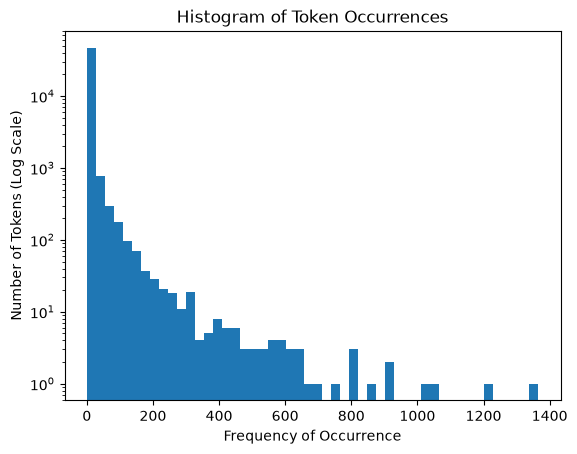

The frequency of occurrence of some tokens are significantly higher than the occurrence of others. 
I notice that the log scaled graph is heavily right skewed.


R^2 on test set: 0.665871843884792
R^2 on training set: 0.7670143724934355 

The symbols with the largest coefficients in absolute value are:
intervention         1.259257
localized            0.824350
thermal              0.747006
crawler              0.696167
background-image:    0.622909
helvetica,           0.598560
aging                0.594956
form.                0.576886
gray;                0.574480
a:active             0.574480
dtype: float64 




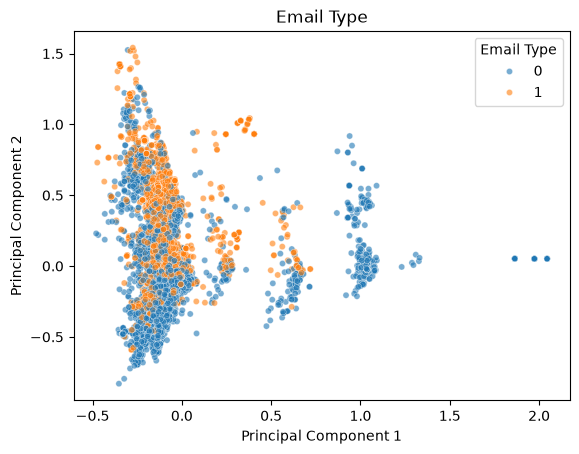

I notice most phishing and non-phishing emails overlap since a two-dimensional grpah cannot capture all the data. 
However, phishing emails seem to stretch with a tail due to shared choice of words for scamming. 
I also notice some outliers that are not part of the main clusters.


R^2 on training sets for PCA: 0.7662354580368254
R^2 on test sets for PCA: 0.668441786659995 

The 2610 principal components give really similar results compared to the original regression results. 
The R^2 for testing is higher and the R^2 for training is lower for the 2610 principal components. 


PCA captures and summarizes the main patterns of the data into fewer data points. 
By reducing the high-dimensional original data and filtering, the model is able to make better predictions, 
run faster, and require less training time.


In [4]:
# Your Phase 1 solution to the problem goes here.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# **Q1.**
# Plot a histogram of the occurrences of tokens. 
# What do you notice about the frequency of occurrence of different tokens? How does it look?

# Get frequencies
frequencies = [freq for token, freq in token_freq]

# Plot a histogram
plt.hist(frequencies, bins=50)
plt.yscale('log')
plt.xlabel("Frequency of Occurrence")
plt.ylabel("Number of Tokens (Log Scale)")
plt.title("Histogram of Token Occurrences")
plt.show()

print('The frequency of occurrence of some tokens are significantly higher than ' \
      'the occurrence of others. \nI notice that the log scaled graph is heavily ' \
      'right skewed.\n\n')


# **Q2.** 
# Load `Phishing_clean.parquet`. This is the text from the e-mails broken 
# into the most common 2,711 tokens and one-hot-encoded as features/covariates. 
# So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam 
# and 0 otherwise, and every other column is a word or symbol that occurs in 
# at least 15 e-mails.
#   1. Perform an 80/20 train-test split of the data.
#   2. Run a regression of $y$ on the one-hot-encoded emails. 
#      What is the $R^2$ on the test set? On the training set?
#   3. What words have the largest coefficients in absolute value 
#      and most strongly influence predictions?
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

# Load text
dfPc = pd.read_parquet('./data/Phishing_clean.parquet')

X = dfPc.drop(columns=['Email Type'])
y = dfPc['Email Type']

# Split the data 80/20
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Regression model
reg = LinearRegression()
reg.fit(X_train, y_train)

train_r2 = reg.score(X_train, y_train)
test_r2 = reg.score(X_test, y_test)

print("R^2 on test set:", test_r2)
print("R^2 on training set:", train_r2, '\n')


# Largest coefficients in absolute value
coefficients = pd.Series(reg.coef_, index=X.columns)
top = coefficients.abs().sort_values(ascending=False).head(10)
print("The symbols with the largest coefficients in absolute value are:")
print(top, '\n\n')


# **Q3.** 
# Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) 
# and perform a principal components analysis decomposition with two components. 
# Plot the first two principal components in a scatter plot, and hue the points by whether 
# they are a phishing scam or not. Do you notice any patterns?
from sklearn.decomposition import PCA
import seaborn as sns

# PCA decomposition
pca = PCA(n_components=2).fit(X)
X_pca = pca.transform(X)


df_pca = pd.DataFrame(X_pca, columns=['PC1', 'PC2'])
df_pca['Email Type'] = y.values
# Scatter plot
sns.scatterplot(
    data = df_pca,
    x='PC1',
    y='PC2',
    hue="Email Type",
    alpha=0.6,
    s=20
)

# Labels and title
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA of Email Tokens (Phishing vs Non-Phishing)")

# Customize legend title to match your colorbar description
plt.title("Email Type")
plt.show()

print("I notice most phishing and non-phishing emails overlap since a " \
      "two-dimensional grpah cannot capture all the data. \nHowever, " \
      "phishing emails seem to stretch with a tail due to shared choice " \
      "of words for scamming. \nI also notice some outliers that are not " \
      "part of the main clusters.\n\n")

# **Q4.**
# Run a linear regression of $y$ on the first 2,610 principal components of $X$. 
# What is the $R^2$ on the training and test sets
# How does this performance compare to the linear regression?

pca_2610 = PCA(n_components=2610)
X_pca_2610 = pca_2610.fit_transform(X)

X_train_pca, X_test_pca, y_train_pca, y_test_pca = train_test_split(
    X_pca_2610, y, test_size=0.2, random_state=42
)

reg_pca = LinearRegression()
reg_pca.fit(X_train_pca, y_train_pca)

train_r2_pca = reg_pca.score(X_train_pca, y_train_pca)
test_r2_pca = reg_pca.score(X_test_pca, y_test_pca)

print("R^2 on training sets for PCA:", train_r2_pca)
print("R^2 on test sets for PCA:", test_r2_pca, '\n')

print('The 2610 principal components give really similar results compared ' \
      'to the original regression results. \nThe R^2 for testing is higher ' \
      'and the R^2 for training is lower for the 2610 principal components. \n\n')


# **Q5.**
# Explain briefly in your own words what the advantage is in using the principal 
# components to run this high-dimensional regression, rather than the original data.

print("PCA captures and summarizes the main patterns of the data into fewer "
      "data points. \nBy reducing the high-dimensional original data and filtering, " \
      "the model is able to make better predictions, \nrun faster, and require " \
      "less training time.")

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [4461eeb534b0efa0cc984c99ac9ad41fbd4e2c92]
- **AI tool and model used:** [ChatGPT]

### *Prompts used

1. [What are things I can do to improve my code and/or explanation to better answer the corresponding questions?]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. Q2: Print signed coefficients alongside token names.
2. Q3: Fix the overwritten plot title and label the legend.
3. Q3: Report explained variance and avoid overinterpreting clusters.
4. Q5: Explain PCA's trade-offs instead of claiming it always improves predictions.

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept | More clearly identifies if the coefficient relates the token to probability of phishing |
| 2 | Reject | No need to overcomplicate with code I am not as familiar with when the current code prints the data out just fine. |
| 3 | Accept | More clearly represents what needs to be said |
| 4 | Reject | Question asks for advantages, did not say to include drawbacks |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

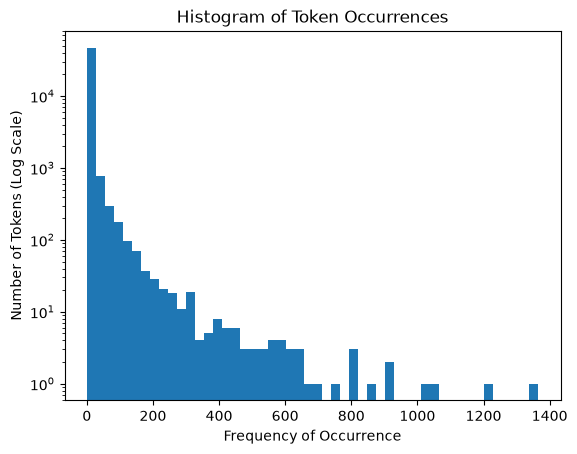

The frequency of occurrence of some tokens are significantly higher than the occurrence of others. 
I notice that the log scaled graph is heavily right skewed.


R^2 on test set: 0.665871843884792
R^2 on training set: 0.7670143724934355 

The symbols with the largest coefficients in absolute value are:
intervention        -1.259257
localized            0.824350
thermal              0.747006
crawler              0.696167
background-image:   -0.622909
helvetica,           0.598560
aging                0.594956
form.                0.576886
gray;               -0.574480
a:active             0.574480
dtype: float64 




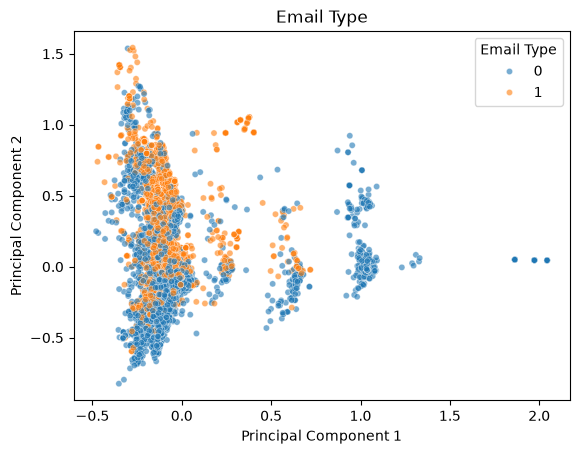

The PCA scatter plot shows substantial overlap between phishing and non-phishing emails in the first two principal components, 
suggesting that the two classes are not clearly separated in this two-dimensional projection. 
There may also be clusters, tails, or outliers that reflect differences in email content. 
However, PCA maximizes the variance captured by the components rather than directly maximizing class separation. 
Therefore, the overlap in this plot does not necessarily mean that the classes 
cannot be distinguished using the full feature set.


R^2 on training sets for PCA: 0.7662354580368254
R^2 on test sets for PCA: 0.668441786659995 

The 2610 principal components give really similar results compared to the original regression results. 
The R^2 for testing is higher and the R^2 for training is lower for the 2610 principal components. 


PCA captures and summarizes the main patterns of the data into fewer data points. 
By reducing the high-dimensional original data and fil

In [5]:
# Your Phase 2 solution to the problem goes here.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# **Q1.**
# Plot a histogram of the occurrences of tokens. 
# What do you notice about the frequency of occurrence of different tokens? How does it look?

# Get frequencies
frequencies = [freq for token, freq in token_freq]

# Plot a histogram
plt.hist(frequencies, bins=50)
plt.yscale('log')
plt.xlabel("Frequency of Occurrence")
plt.ylabel("Number of Tokens (Log Scale)")
plt.title("Histogram of Token Occurrences")
plt.show()

print('The frequency of occurrence of some tokens are significantly higher than ' \
      'the occurrence of others. \nI notice that the log scaled graph is heavily ' \
      'right skewed.\n\n')


# **Q2.** 
# Load `Phishing_clean.parquet`. This is the text from the e-mails broken 
# into the most common 2,711 tokens and one-hot-encoded as features/covariates. 
# So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam 
# and 0 otherwise, and every other column is a word or symbol that occurs in 
# at least 15 e-mails.
#   1. Perform an 80/20 train-test split of the data.
#   2. Run a regression of $y$ on the one-hot-encoded emails. 
#      What is the $R^2$ on the test set? On the training set?
#   3. What words have the largest coefficients in absolute value 
#      and most strongly influence predictions?
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

# Load text
dfPc = pd.read_parquet('./data/Phishing_clean.parquet')

X = dfPc.drop(columns=['Email Type'])
y = dfPc['Email Type']

# Split the data 80/20
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Regression model
reg = LinearRegression()
reg.fit(X_train, y_train)

train_r2 = reg.score(X_train, y_train)
test_r2 = reg.score(X_test, y_test)

print("R^2 on test set:", test_r2)
print("R^2 on training set:", train_r2, '\n')


# Largest coefficients in absolute value
coefficients = pd.Series(reg.coef_, index=X.columns)
top = coefficients.loc[
    coefficients.abs().nlargest(10).index
]
print("The symbols with the largest coefficients in absolute value are:")
print(top, '\n\n')


# **Q3.** 
# Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) 
# and perform a principal components analysis decomposition with two components. 
# Plot the first two principal components in a scatter plot, and hue the points by whether 
# they are a phishing scam or not. Do you notice any patterns?
from sklearn.decomposition import PCA
import seaborn as sns

# PCA decomposition
pca = PCA(n_components=2).fit(X)
X_pca = pca.transform(X)


df_pca = pd.DataFrame(X_pca, columns=['PC1', 'PC2'])
df_pca['Email Type'] = y.values
# Scatter plot
sns.scatterplot(
    data = df_pca,
    x='PC1',
    y='PC2',
    hue="Email Type",
    alpha=0.6,
    s=20
)

# Labels and title
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA of Email Tokens (Phishing vs Non-Phishing)")

# Customize legend title to match your colorbar description
plt.title("Email Type")
plt.show()

print("The PCA scatter plot shows substantial overlap between phishing "
      "and non-phishing emails in the first two principal components, \n"
      "suggesting that the two classes are not clearly separated in "
      "this two-dimensional projection. \nThere may also be clusters, "
      "tails, or outliers that reflect differences in email content. \n"
      "However, PCA maximizes the variance captured by the components "
      "rather than directly maximizing class separation. \nTherefore, "
      "the overlap in this plot does not necessarily mean that the "
      "classes \ncannot be distinguished using the full feature set.\n\n")

# **Q4.**
# Run a linear regression of $y$ on the first 2,610 principal components of $X$. 
# What is the $R^2$ on the training and test sets
# How does this performance compare to the linear regression?

pca_2610 = PCA(n_components=2610)
X_pca_2610 = pca_2610.fit_transform(X)

X_train_pca, X_test_pca, y_train_pca, y_test_pca = train_test_split(
    X_pca_2610, y, test_size=0.2, random_state=42
)

reg_pca = LinearRegression()
reg_pca.fit(X_train_pca, y_train_pca)

train_r2_pca = reg_pca.score(X_train_pca, y_train_pca)
test_r2_pca = reg_pca.score(X_test_pca, y_test_pca)

print("R^2 on training sets for PCA:", train_r2_pca)
print("R^2 on test sets for PCA:", test_r2_pca, '\n')

print('The 2610 principal components give really similar results compared ' \
      'to the original regression results. \nThe R^2 for testing is higher ' \
      'and the R^2 for training is lower for the 2610 principal components. \n\n')


# **Q5.**
# Explain briefly in your own words what the advantage is in using the principal 
# components to run this high-dimensional regression, rather than the original data.

print("PCA captures and summarizes the main patterns of the data into fewer "
      "data points. \nBy reducing the high-dimensional original data and filtering, " \
      "the model is able to make better predictions, \nrun faster, and require " \
      "less training time.")

### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]

Artificial Intelligence (AI) helped me express my explanations more clearly by adding details that support my claim. It also made my explanations easier to understand. In addition, it made suggestions to make my code look more visually appealing, but these changes are unnecessary sometimes since they make the code more complicated and harder to follow.


To verify the solution, I compared my phase 1 answers to the phase 2 answers. If there were any differences, I looked back on the slides to see what I might need to fix. Each response was evaluated to ensure that the prompt was directly answered.


Some limitations of AI are that it doesn't know my coding style and has a very general way of writing. Sometimes, it gives feedback that may not necessarily benefit my code, but make it look more complicated and confusing to me. AI pointed out some things in this code that I did not want to change but can look out for next time.


Regarding concerns, it is important to verify the answers and suggestions given by AI before actually implementing any of them.
